In [16]:
import pandas as pd

import matplotlib.pyplot as plt

df = pd.read_csv("nasdaq100.csv", sep=";")

In [17]:
df.head()

,Date,Starting (USD),Ending (USD)
0,01.01.24,16800,16500
1,01.12.23,15900,16100
2,01.11.23,15800,15300
3,01.10.23,16100,16200
4,01.09.23,16300,15700


In [18]:
df.tail()

,Date,Starting (USD),Ending (USD)
7,01.06.23,15800,15500
8,01.05.23,16150,16100
9,01.04.23,16300,15800
10,01.03.23,16200,16200
11,01.02.23,16300,15700


In [19]:
display(df.shape)

(12, 3)

In [20]:
display(df.columns)

Index(['Date', 'Starting (USD)', 'Ending (USD)'], dtype='object')

In [21]:
display(df)

,Date,Starting (USD),Ending (USD)
0,01.01.24,16800,16500
1,01.12.23,15900,16100
2,01.11.23,15800,15300
3,01.10.23,16100,16200
4,01.09.23,16300,15700
5,01.08.23,16800,16400
6,01.07.23,15900,16200
7,01.06.23,15800,15500
8,01.05.23,16150,16100
9,01.04.23,16300,15800


In [22]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Date              0
Starting (USD)    0
Ending (USD)      0
dtype: int64


In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Date            12 non-null     object
 1   Starting (USD)  12 non-null     int64 
 2   Ending (USD)    12 non-null     int64 
dtypes: int64(2), object(1)
memory usage: 416.0+ bytes


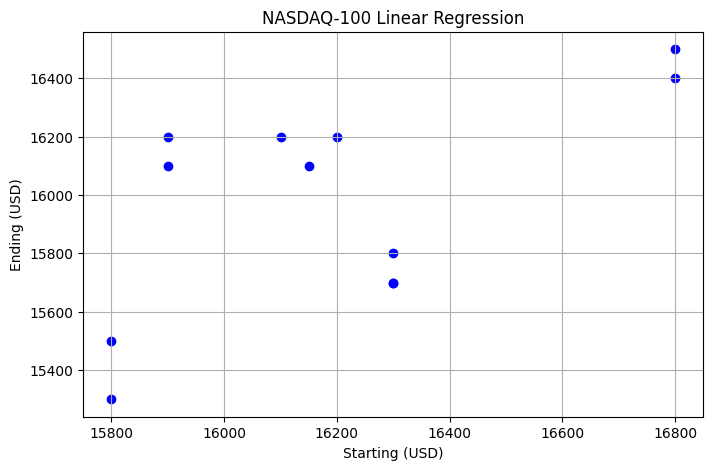

In [24]:
x= df["Starting (USD)"]
y= df["Ending (USD)"]

plt.figure(figsize=(8, 5))

plt.scatter(x,y,color="blue")

plt.xlabel("Starting (USD)")
plt.ylabel("Ending (USD)")

plt.title("NASDAQ-100 Linear Regression")
plt.grid(True)

plt.show()

In [26]:
from sklearn.linear_model import LinearRegression
x = df[["Starting (USD)"]]
y = df["Ending (USD)"]

model = LinearRegression()

model.fit(x,y)
print("Model Training Completed!")

Model Training Completed!


In [28]:
print("X Shape:", x.shape)
print("y Shape:", y.shape)


X Shape: (12, 1)
y Shape: (12,)


In [29]:
print("Coefficient (m):", model.coef_[0]) #slope ber kore
print("Intercept (c):", model.intercept_)


Coefficient (m): 0.6525829344776366
Intercept (c): 5405.875557022609


In [30]:

# New starting price
new_data = pd.DataFrame({
    "Starting (USD)": [16000]
})

# Predict ending price
prediction = model.predict(new_data)

print("Predicted Ending Price:", prediction[0])

Predicted Ending Price: 15847.202508664795


In [ ]:
new_data = pd.DataFrame({
    "Starting (USD)": [17000]
})

prediction = model.predict(new_data)

print("Predicted Ending Price:", prediction[0])

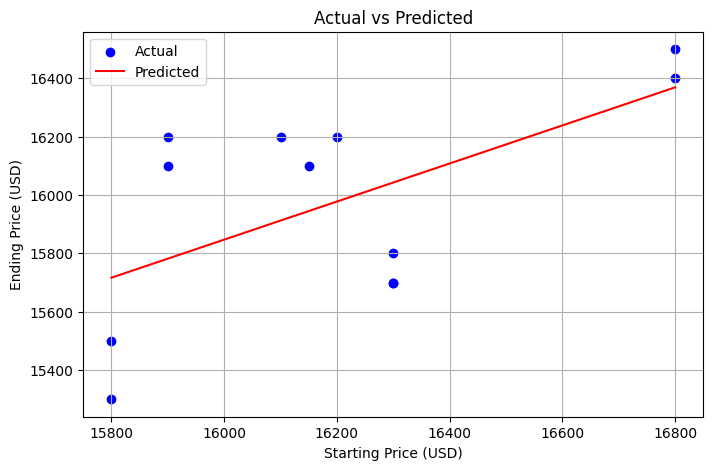

In [31]:
# Predict all training data
y_pred = model.predict(x)

# Sort X values for a smooth regression line
sorted_index = x["Starting (USD)"].argsort()

plt.figure(figsize=(8, 5))

# Actual data
plt.scatter(x["Starting (USD)"], y, color="blue", label="Actual")

# Predicted regression line
plt.plot(
    x["Starting (USD)"].iloc[sorted_index],
    y_pred[sorted_index],
    color="red",
    label="Predicted"
)

plt.xlabel("Starting Price (USD)")
plt.ylabel("Ending Price (USD)")
plt.title("Actual vs Predicted")
plt.legend()
plt.grid(True)
plt.show()


In [32]:

from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y, y_pred)

print("Mean Absolute Error:", mae)


Mean Absolute Error: 260.3840017604666


In [33]:

from sklearn.metrics import r2_score

r2 = r2_score(y, y_pred)

print("R2 Score:", r2)

R2 Score: 0.3577804940272571


In [34]:
actual = 16000
predicted = 15800

loss = (actual - predicted) ** 2

print("Loss:", loss)

Loss: 40000


In [35]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(y, y_pred)

print("Mean Squared Error:", mse)


Mean Squared Error: 80411.23397700385


In [36]:
import numpy as np

x_small = np.array([1, 2, 3])
y_small = np.array([2, 4, 6])

m = 0.0
c = 0.0
learning_rate = 0.1

# Calculate initial predictions and cost
predictions = m * x_small + c
errors = predictions - y_small

cost_before = np.mean(errors ** 2)

# Calculate gradients
dm = 2 * np.mean(x_small * errors)
dc = 2 * np.mean(errors)

# Update slope and intercept
m = m - learning_rate * dm
c = c - learning_rate * dc

# Calculate new cost
new_predictions = m * x_small + c
cost_after = np.mean((new_predictions - y_small) ** 2)

print("Cost Before:", round(cost_before, 2))
print("Cost After:", round(cost_after, 2))
print("New m:", round(m, 4))
print("New c:", round(c, 4))


Cost Before: 18.67
Cost After: 0.3
New m: 1.8667
New c: 0.8
